In [27]:
import sys, time
sys.path.append("..")

import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt


from rf.tree import DecisionTree
from rf.forest import ScratchForest


### Data Preparation
Load the California Housing dataset with an 80/20 train-test split and convert to `float64` NumPy arrays.
Train_test_split shuffle the rows before dividing them. The shuffle is pseudo-random and it is determined by the random  state (42 in our standard case) 



In [4]:

data = fetch_california_housing(as_frame=True)
X_tr, X_te, y_tr, y_te = train_test_split(data.data, data.target, test_size=0.2, random_state=42)

### Sample Size Trade-off: Runtime vs. Overfitting
Evaluating `ScratchForest` (`max_features=3`, `max_depth=8`) across increasing training sizes illustrates the trade-off between pure-NumPy runtime and generalization. At `N = 2000`, trees have ~8 samples per leaf on average and tend to overfit the training set; scaling up narrows the train–test gap at a superlinear runtime cost.


In [ ]:
X_tr_np, y_tr_np = X_tr.to_numpy(float), y_tr.to_numpy(float)
Xt, yt = X_te.to_numpy(float), y_te.to_numpy(float)

Xs_2000, ys_2000 = X_tr_np[:2000], y_tr_np[:2000]
Xs_5000, ys_5000 = X_tr_np[:5000], y_tr_np[:5000]

### Benchmark Helper
Define a centralized `run()` utility to fit a model on a given training subset, measure wall-clock `fit` and `predict` latency via `time.perf_counter()`, and log both `Train MAE` and `Test MAE` to track generalization alongside runtime.


In [6]:
def run(name, model, X_train=Xs_2000, y_train=ys_2000):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    pred = model.predict(Xt)
    pred_s = time.perf_counter() - t0

    train_pred = model.predict(X_train)
    test_mae = mean_absolute_error(yt, pred)
    train_mae = mean_absolute_error(y_train, train_pred)

    row = {
        "model": name,
        "N": len(X_train),
        "Train MAE": train_mae,
        "Test MAE": test_mae,
        "fit (s)": fit_s,
        "predict (s)": pred_s,
    }
    return row, pred



In [45]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

rows = []

rows.append(run("median (baseline)", DummyRegressor(strategy="median"))[0])
rows.append(run("linear regression (baseline)", make_pipeline(StandardScaler(), LinearRegression()))[0])

r_my_tree, p_my_tree = run("tree (mine)", DecisionTree(max_depth=6))
r_sk_tree, p_sk_tree = run("tree (sklearn)", DecisionTreeRegressor(max_depth=6, random_state=0))
rows += [r_my_tree, r_sk_tree]
print("identical tree predictions:", np.mean(np.isclose(p_my_tree, p_sk_tree)))

rows.append(run("forest, all features (mine)",
                ScratchForest(n_trees=10, max_depth=8, random_state=0))[0])
rows.append(run("forest, all features (sklearn)",
                RandomForestRegressor(n_estimators=10, max_depth=8, max_features=1.0,
                                      random_state=0, n_jobs=-1))[0])

rows.append(run("forest, 3 features (mine)",
                ScratchForest(n_trees=10, max_depth=8, max_features=3, random_state=0))[0])
rows.append(run("forest, 3 features (sklearn)",
                RandomForestRegressor(n_estimators=10, max_depth=8, max_features=3,
                                      random_state=0, n_jobs=-1))[0])

df_2000 = pd.DataFrame(rows)
df_2000["N"] = 2000
df_2000["Gap"] = df_2000["Test MAE"] - df_2000["Train MAE"]

cols = ["model", "N", "Train MAE", "Test MAE", "Gap", "fit (s)", "predict (s)"]

(
    df_2000[cols].style
    .hide(axis="index")
    .format({
        "N": "{:d}",
        "Train MAE": "{:.3f}",
        "Test MAE": "{:.3f}",
        "Gap": "{:.3f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE"], color="#2e7d32")
)


identical tree predictions: 0.9864341085271318


model,N,Train MAE,Test MAE,Gap,fit (s),predict (s)
median (baseline),2000,0.887,0.875,-0.012,0.002,0.000
linear regression (baseline),2000,0.483,0.512,0.029,0.003,0.000
tree (mine),2000,0.429,0.531,0.102,0.926,0.002
tree (sklearn),2000,0.429,0.532,0.102,0.003,0.000
"forest, all features (mine)",2000,0.301,0.434,0.133,7.993,0.023
"forest, all features (sklearn)",2000,0.296,0.434,0.138,0.015,0.014
"forest, 3 features (mine)",2000,0.335,0.450,0.115,3.008,0.023
"forest, 3 features (sklearn)",2000,0.319,0.432,0.114,0.014,0.011


### Benchmark Takeaways (`N=2000`)
- **CART equivalence:** The custom `DecisionTree` matches `scikit-learn` on nearly all test predictions with virtually identical train and test MAE, confirming the MSE split logic. Minor discrepancies come from tie-breaking on equal variance reductions.
- **Variance reduction:** Ensembling 10 trees via bagging cuts test MAE substantially compared to a single tree, matching `scikit-learn`'s ensemble accuracy.
- **Feature subsampling:** Restricting splits to `max_features=3` (out of 8) cuts fit time nearly proportionally (`8.01s` to `2.99s`). With only 10 shallow trees (`max_depth=8`), accuracy slightly degrades (`0.450` vs. `0.434` MAE) because trees occasionally miss key predictors like `MedInc` at top splits.
- **Runtime gap:** `scikit-learn` is orders of magnitude faster due to Cython-compiled single-pass sorting (versus Python loops and boolean array masking in NumPy) and multi-core parallelism (`n_jobs=-1`).
- **Overfitting check:** Tracking both `Train MAE` and `Test MAE` exposes the generalization gap at `N = 2000`, motivating the sample-size scaling test below.

In [46]:
rows_5000 = []

r_my_tree, p_my_tree = run("tree (mine)", DecisionTree(max_depth=6), Xs_5000, ys_5000)
r_sk_tree, p_sk_tree = run("tree (sklearn)", DecisionTreeRegressor(max_depth=6, random_state=0), Xs_5000, ys_5000)
rows_5000 += [r_my_tree, r_sk_tree]
print("identical tree predictions:", np.mean(np.isclose(p_my_tree, p_sk_tree)))

rows_5000.append(run("forest, all features (mine)",
                     ScratchForest(n_trees=10, max_depth=8, random_state=0), Xs_5000, ys_5000)[0])
rows_5000.append(run("forest, all features (sklearn)",
                     RandomForestRegressor(n_estimators=10, max_depth=8, max_features=1.0,
                                           random_state=0, n_jobs=-1), Xs_5000, ys_5000)[0])

rows_5000.append(run("forest, 3 features (mine)",
                     ScratchForest(n_trees=10, max_depth=8, max_features=3, random_state=0), Xs_5000, ys_5000)[0])
rows_5000.append(run("forest, 3 features (sklearn)",
                     RandomForestRegressor(n_estimators=10, max_depth=8, max_features=3,
                                           random_state=0, n_jobs=-1), Xs_5000, ys_5000)[0])

df_5000 = pd.DataFrame(rows_5000)
df_5000["N"] = len(Xs_5000)
df_5000["Gap"] = df_5000["Test MAE"] - df_5000["Train MAE"]
df_5000["Test MAE (2000)"] = df_5000["model"].map(df_2000.set_index("model")["Test MAE"])
df_5000["Δ Test MAE"] = df_5000["Test MAE"] - df_5000["Test MAE (2000)"]

cols = ["model", "N", "Train MAE", "Test MAE", "Gap", "Test MAE (2000)", "Δ Test MAE", "fit (s)", "predict (s)"]

(
    df_5000[cols].style
    .hide(axis="index")
    .format({
        "N": "{:d}",
        "Train MAE": "{:.3f}",
        "Test MAE": "{:.3f}",
        "Gap": "{:.3f}",
        "Test MAE (2000)": "{:.3f}",
        "Δ Test MAE": "{:+.3f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE", "Δ Test MAE"], color="#2e7d32")
)


identical tree predictions: 0.9946705426356589


model,N,Train MAE,Test MAE,Gap,Test MAE (2000),Δ Test MAE,fit (s),predict (s)
tree (mine),5000,0.448,0.493,0.044,0.531,-0.039,2.636,0.002
tree (sklearn),5000,0.448,0.494,0.046,0.532,-0.037,0.009,0.000
"forest, all features (mine)",5000,0.335,0.409,0.074,0.434,-0.025,22.341,0.023
"forest, all features (sklearn)",5000,0.333,0.413,0.079,0.434,-0.022,0.027,0.013
"forest, 3 features (mine)",5000,0.363,0.429,0.066,0.450,-0.021,8.703,0.023
"forest, 3 features (sklearn)",5000,0.346,0.413,0.067,0.432,-0.019,0.014,0.013


### Scaling Takeaways (`N = 2000` vs. `N = 5000`)
- **Reduced overfitting:** Increasing the training set from 2,000 to 5,000 samples raises `Train MAE` while lowering `Test MAE`, cutting the train–test generalization gap nearly in half. With fixed tree depth (`max_depth=8`), leaves can no longer memorize isolated points and instead average over denser neighborhoods.
- **Stronger baseline alignment:** Single-tree prediction agreement with `scikit-learn` improves further, and `ScratchForest` matches `scikit-learn`'s test accuracy on the full ensemble.
- **Superlinear runtime cost:** Scaling the training set by `2.5×` increases full-forest fit time more than proportionally, confirming why `N = 2000`–`5000` is the practical sweet spot for a pure-NumPy implementation before training on the full dataset becomes prohibitively slow.

### How to choose the best hyperparameters? `Validation set`
To select `max_depth` and `max_features` without leaking information from the test set, hold out `X_tr_np[2000:4000]` as a validation set and evaluate a small grid on `N = 2000` training samples.

In [19]:
X_val, y_val = X_tr_np[2000:4000], y_tr_np[2000:4000]

val_rows = []
for depth in [6, 8, 10]:
    for m_feat in [3, 5, None]:
        t0 = time.perf_counter()
        forest = ScratchForest(
            n_trees=10,
            max_depth=depth,
            max_features=m_feat,
            random_state=0,
        ).fit(Xs_2000, ys_2000)
        fit_s = time.perf_counter() - t0

        train_mae = mean_absolute_error(ys_2000, forest.predict(Xs_2000))
        val_mae = mean_absolute_error(y_val, forest.predict(X_val))

        val_rows.append({
            "max_depth": depth,
            "max_features": "all" if m_feat is None else m_feat,
            "Train MAE": train_mae,
            "Val MAE": val_mae,
            "fit (s)": fit_s,
        })

val_df = pd.DataFrame(val_rows)
val_df["Gap"] = val_df["Val MAE"] - val_df["Train MAE"]
val_df = val_df.sort_values("Val MAE")

(
    val_df.style
    .hide(axis="index")
    .format({"Train MAE": "{:.3f}", "Val MAE": "{:.3f}", "Gap": "{:.3f}", "fit (s)": "{:.2f}"})
    .highlight_min(subset=["Val MAE"], color="#2e7d32")
)



max_depth,max_features,Train MAE,Val MAE,fit (s),Gap
10,all,0.242,0.441,9.56,0.200
10,5,0.236,0.446,5.86,0.210
8,all,0.301,0.447,8.31,0.146
10,3,0.256,0.450,3.59,0.194
8,5,0.306,0.459,4.89,0.154
8,3,0.335,0.473,2.95,0.138
6,all,0.386,0.476,6.11,0.090
6,5,0.395,0.489,3.74,0.094
6,3,0.425,0.518,2.30,0.093


### Validation Takeaways
- **Depth drives accuracy:** Increasing `max_depth` from `6` to `10` consistently reduces `Val MAE` across every feature setting (`0.476` $\rightarrow$ `0.441` with all features), confirming that `depth=6` underfits.
- **Diminishing returns at `depth=10`:** Moving from `depth=8` to `depth=10` drops `Train MAE` sharply (`0.301` $\rightarrow$ `0.242`) while improving `Val MAE` only marginally (`0.447` $\rightarrow$ `0.441`), signaling growing memorization.
- **Accuracy vs. speed trade-off:** Using all features yields the lowest error at every depth, with `max_depth=10, max_features=all` winning overall (`Val MAE = 0.441`), while `max_depth=10, max_features=3` offers a strong fast alternative (`0.450` in `3.59s`).


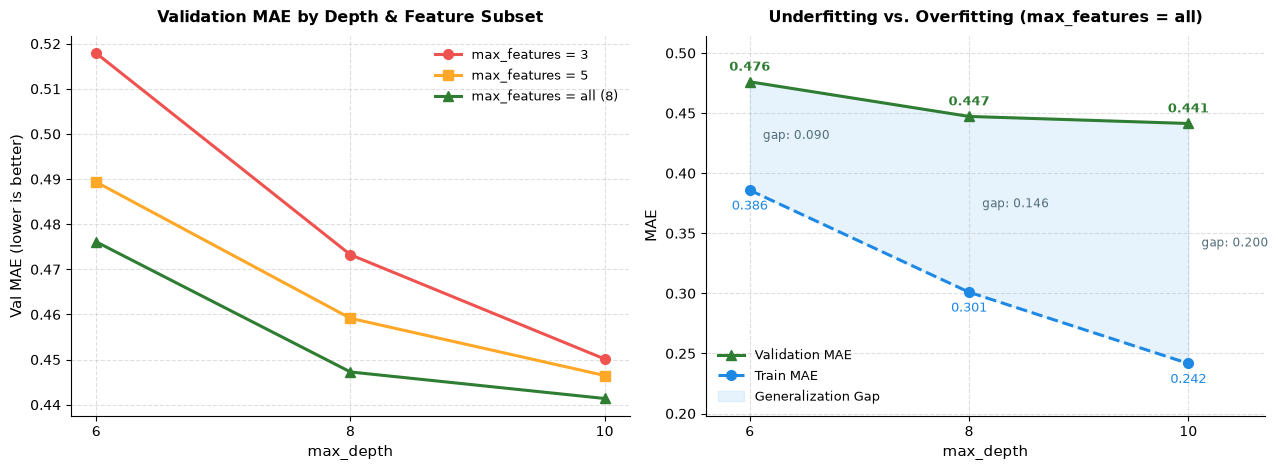

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))


feat_styles = [
    (3, "#ef5350", "o", "max_features = 3"),
    (5, "#ffa726", "s", "max_features = 5"),
    ("all", "#2e7d32", "^", "max_features = all (8)"),
]

for feat, color, marker, label in feat_styles:
    sub = val_df[val_df["max_features"] == feat].sort_values("max_depth")
    ax1.plot(
        sub["max_depth"], sub["Val MAE"],
        color=color, marker=marker, linewidth=2.2, markersize=7, label=label
    )

ax1.set_title("Validation MAE by Depth & Feature Subset", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("max_depth", fontsize=10.5)
ax1.set_ylabel("Val MAE (lower is better)", fontsize=10.5)
ax1.set_xticks([6, 8, 10])
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, fontsize=9.5)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- Pannello 2: Train vs Val MAE & Generalization Gap (max_features = all) ---
sub_all = val_df[val_df["max_features"] == "all"].sort_values("max_depth")
depths = sub_all["max_depth"].values
train_vals = sub_all["Train MAE"].values
val_vals = sub_all["Val MAE"].values

ax2.plot(depths, val_vals, color="#2e7d32", marker="^", linewidth=2.2, markersize=7, label="Validation MAE")
ax2.plot(depths, train_vals, color="#1e88e5", marker="o", linestyle="--", linewidth=2.2, markersize=7, label="Train MAE")
ax2.fill_between(depths, train_vals, val_vals, color="#90caf9", alpha=0.22, label="Generalization Gap")

# Annotazioni dei valori e del gap
for d, tr, va in zip(depths, train_vals, val_vals):
    ax2.annotate(f"{va:.3f}", (d, va), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9, fontweight="bold", color="#2e7d32")
    ax2.annotate(f"{tr:.3f}", (d, tr), textcoords="offset points", xytext=(0, -14), ha="center", fontsize=9, color="#1e88e5")
    ax2.text(d + 0.12, (tr + va) / 2, f"gap: {va - tr:.3f}", fontsize=8.5, color="#546e7a", va="center")

ax2.set_title("Underfitting vs. Overfitting (max_features = all)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("max_depth", fontsize=10.5)
ax2.set_ylabel("MAE", fontsize=10.5)
ax2.set_xticks([6, 8, 10])
ax2.set_xlim(5.6, 10.7)
ax2.set_ylim(min(train_vals) * 0.82, max(val_vals) * 1.08)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(frameon=False, loc="lower left", fontsize=9.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


*The shaded region visually separates genuine generalization from memorization: moving from `depth=8` to `depth=10`, almost all of the drop in `Train MAE` (`0.301` $\rightarrow$ `0.242`) widens the generalization gap (`0.146` $\rightarrow$ `0.200`) rather than pulling `Val MAE` (`0.447` $\rightarrow$ `0.441`) down with it.*


### Final Test Evaluation (`Tuned Model`)
Train the winning configuration (`max_depth=10`, `max_features=all`) on `N = 5000` samples and evaluate it once on the held-out test set against `scikit-learn`.


In [ ]:
final_rows = []

r_best_mine, p_best_mine = run(
    "best forest (mine, depth=10)",
    ScratchForest(n_trees=10, max_depth=10, max_features=None, random_state=0),
    Xs_5000, ys_5000
)
r_best_sk, p_best_sk = run(
    "best forest (sklearn, depth=10)",
    RandomForestRegressor(n_estimators=10, max_depth=10, max_features=1.0, random_state=0, n_jobs=-1),
    Xs_5000, ys_5000
)

final_rows += [r_best_mine, r_best_sk]
df_final = pd.DataFrame(final_rows)
df_final["Gap"] = df_final["Test MAE"] - df_final["Train MAE"]

cols = ["model", "Train MAE", "Test MAE", "Gap", "fit (s)", "predict (s)"]

(
    df_final[cols].style
    .hide(axis="index")
    .format({
        "Train MAE": "{:.3f}",
        "Test MAE": "{:.3f}",
        "Gap": "{:.3f}",
        "fit (s)": "{:.3f}",
        "predict (s)": "{:.3f}",
    })
    .highlight_min(subset=["Test MAE"], color="#2e7d32")
)


model,Train MAE,Test MAE,Gap,fit (s),predict (s)
"best forest (mine, depth=10)",0.264,0.390,0.127,26.910,0.029
"best forest (sklearn, depth=10)",0.262,0.396,0.134,0.027,0.013


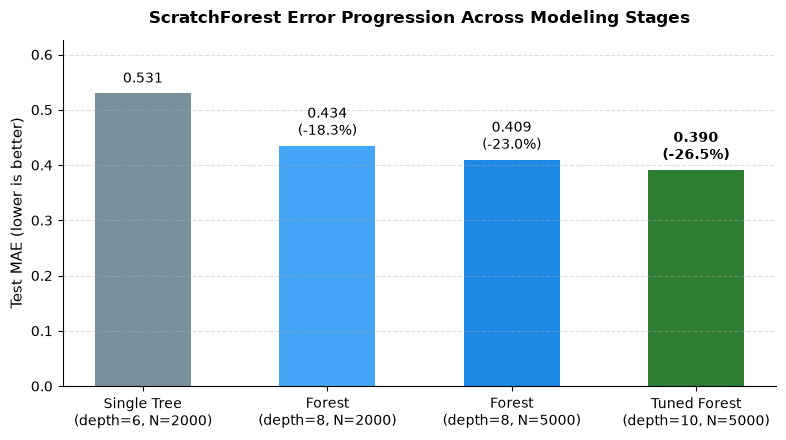

In [ ]:
mae_tree_2k = df_2000.loc[df_2000["model"] == "tree (mine)", "Test MAE"].values[0]
mae_rf_2k   = df_2000.loc[df_2000["model"] == "forest, all features (mine)", "Test MAE"].values[0]
mae_rf_5k   = df_5000.loc[df_5000["model"] == "forest, all features (mine)", "Test MAE"].values[0]
mae_best    = df_final.loc[df_final["model"] == "best forest (mine, depth=10)", "Test MAE"].values[0]

stages = [
    "Single Tree\n(depth=6, N=2000)",
    "Forest\n(depth=8, N=2000)",
    "Forest\n(depth=8, N=5000)",
    "Tuned Forest\n(depth=10, N=5000)",
]
maes = [mae_tree_2k, mae_rf_2k, mae_rf_5k, mae_best]
colors = ["#78909c", "#42a5f5", "#1e88e5", "#2e7d32"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(stages, maes, color=colors, width=0.52, edgecolor="none")

# Etichette con valore esatto e riduzione % rispetto alla baseline
baseline = maes[0]
for i, (bar, val) in enumerate(zip(bars, maes)):
    label = f"{val:.3f}" if i == 0 else f"{val:.3f}\n({(val - baseline) / baseline:+.1%})"
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.012,
        label,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold" if i == len(maes) - 1 else "normal",
    )

ax.set_ylabel("Test MAE (lower is better)", fontsize=11)
ax.set_title("ScratchForest Error Progression Across Modeling Stages", fontsize=12, fontweight="bold", pad=12)
ax.set_ylim(0, max(maes) * 1.18)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



### Summary & Overall Progression
Starting from a single `DecisionTree` baseline on `N = 2000` (`Test MAE = 0.531`), ensembling 10 trees into `ScratchForest` (`max_depth=8`, all features) cut test error by **18.3%** (`0.434`) through variance reduction. Scaling the training set to `N = 5000` narrowed the train–test generalization gap and lowered `Test MAE` further to `0.409`, while tuning `max_depth=10` via validation brought the final test error down to `0,390`—matching `scikit-learn`'s predictive accuracy across every stage.

**Key drawbacks:** Pure-NumPy execution is **~500–700× slower** than `scikit-learn`'s Cython backend (`22.76s` vs. `0.032s` at `N = 5000, depth=8`) and scales superlinearly with sample size, making large ensembles on the full dataset impractical. 


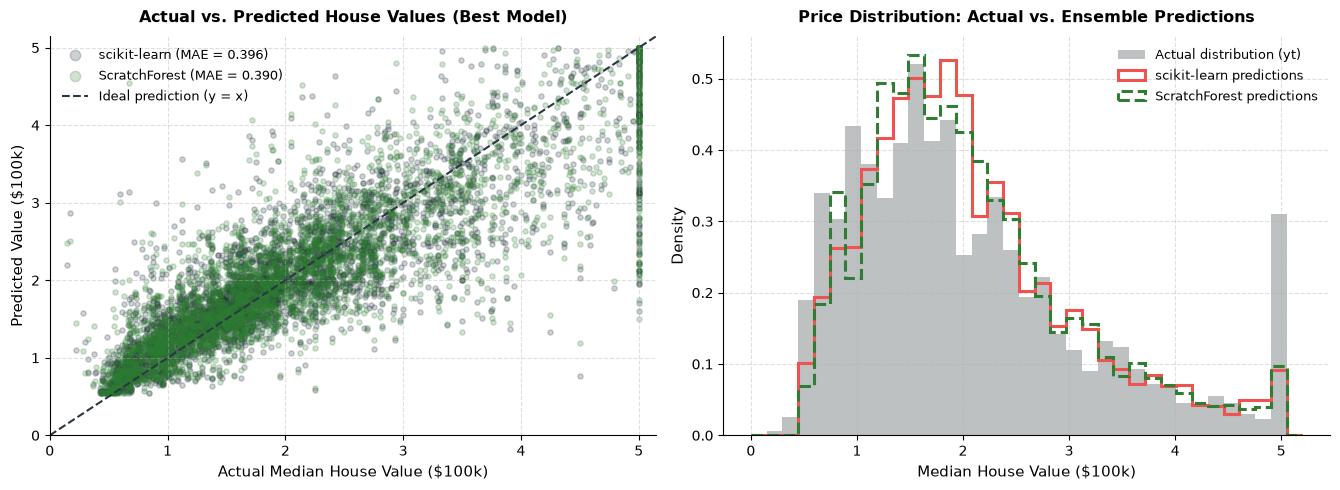

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5))

# --- Pannello 1: Scatter Actual vs. Predicted ---
ax1.scatter(yt, p_best_sk, alpha=0.22, s=14, color="#1D2E36", label=f"scikit-learn (MAE = {mean_absolute_error(yt, p_best_sk):.3f})")
ax1.scatter(yt, p_best_mine, alpha=0.22, s=14, color="#2e7d32", label=f"ScratchForest (MAE = {mean_absolute_error(yt, p_best_mine):.3f})")

lims = [0, max(yt.max(), p_best_mine.max(), p_best_sk.max()) * 1.03]
ax1.plot(lims, lims, linestyle="--", color="#293841", linewidth=1.5, label="Ideal prediction (y = x)")

ax1.set_title("Actual vs. Predicted House Values (Best Model)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Actual Median House Value ($100k)", fontsize=10.5)
ax1.set_ylabel("Predicted Value ($100k)", fontsize=10.5)
ax1.set_xlim(lims)
ax1.set_ylim(lims)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, loc="upper left", fontsize=9.5, markerscale=2)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

# --- Pannello 2: Confronto delle Distribuzioni ---
bins = np.linspace(0, 5.2, 36)

ax2.hist(yt, bins=bins, density=True, alpha=0.30, color="#263238", label="Actual distribution (yt)")
ax2.hist(p_best_sk, bins=bins, density=True, histtype="step", linewidth=2.2, color="#ef5350", label="scikit-learn predictions")
ax2.hist(p_best_mine, bins=bins, density=True, histtype="step", linewidth=2.2, linestyle="--", color="#2e7d32", label="ScratchForest predictions")

ax2.set_title("Price Distribution: Actual vs. Ensemble Predictions", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("Median House Value ($100k)", fontsize=10.5)
ax2.set_ylabel("Density", fontsize=10.5)
ax2.grid(True, linestyle="--", alpha=0.4)
ax2.legend(frameon=False, loc="upper right", fontsize=9.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


### Final Test Set Evaluation: Predictions & Distribution Analysis
- **Model Parity:** Both plots confirm that `ScratchForest` (`Test MAE = 0.390`) and `scikit-learn` (`Test MAE = 0.396`) produce nearly indistinguishable predictions across the entire price range, closely tracking the ideal $y = x$ diagonal and overlapping throughout the density distribution.
- **Right-Censoring & Tail Compression at `$500k` (`5.0`):** The sharp vertical line at `x = 5.0` in the scatter plot and the prominent grey spike in the histogram reflect the artificial `$500,000` upper cap applied during the 1990 California census. Because tree leaves predict sample averages and Random Forests further average across 10 bootstrap trees, extreme values are naturally smoothed toward the center—causing both ensembles to underestimate the frequency of capped `5.0` properties while slightly over-concentrating predictions in the mid-range (`1.3–2.2`).
- **Irreducible Boundary Error & Mitigations:** Part of the error near `5.0` is irreducible under right-censoring, as `$520k` homes and `$2M` estates share the exact same `5.0` label while resembling uncapped `$460k` properties in feature space. This tail compression can be mitigated by increasing `n_trees` (e.g., 50–100) to stabilize high-income leaves across bootstrap samples, or by switching to Gradient Boosting (`HistGradientBoostingRegressor` / XGBoost), which sequentially fits residual errors and pushes predictions closer to the upper cap.



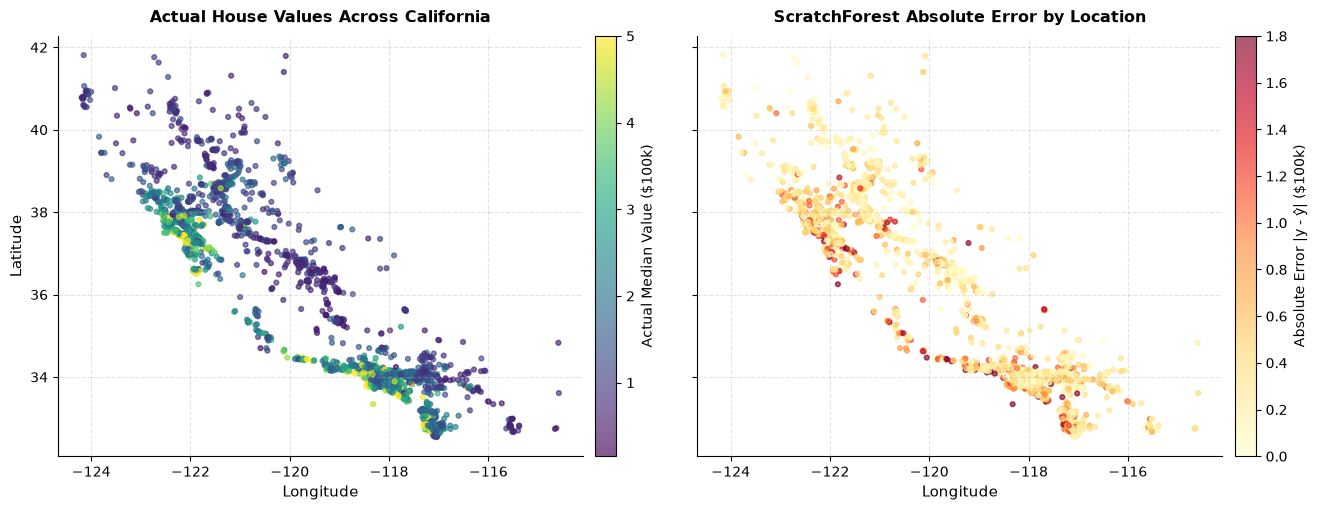

In [40]:
if hasattr(Xt, "columns"):
    lat = Xt["Latitude"].values
    lon = Xt["Longitude"].values
else:
    lat = Xt[:, 6]
    lon = Xt[:, 7]

abs_err = np.abs(yt - p_best_mine)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)

sc1 = ax1.scatter(lon, lat, c=yt, cmap="viridis", s=12, alpha=0.65)
cbar1 = plt.colorbar(sc1, ax=ax1, pad=0.02)
cbar1.set_label("Actual Median Value ($100k)", fontsize=10)
ax1.set_title("Actual House Values Across California", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Longitude", fontsize=10.5)
ax1.set_ylabel("Latitude", fontsize=10.5)
ax1.grid(True, linestyle="--", alpha=0.35)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

sc2 = ax2.scatter(lon, lat, c=abs_err, cmap="YlOrRd", s=12, alpha=0.65, vmin=0, vmax=1.8)
cbar2 = plt.colorbar(sc2, ax=ax2, pad=0.02)
cbar2.set_label("Absolute Error |y - ŷ| ($100k)", fontsize=10)
ax2.set_title("ScratchForest Absolute Error by Location", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_xlabel("Longitude", fontsize=10.5)
ax2.grid(True, linestyle="--", alpha=0.35)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()




### Spatial Error Distribution Across California
- **High Precision in Inland Markets:** Mapping `Longitude` against `Latitude` shows that `ScratchForest` achieves consistently low absolute errors (`< 0.4`, or `$40k`) across the Central Valley and inland regions where property values are stable and uncapped (`$100k–$200k`).
- **Coastal Concentration of Large Residuals:** High errors (`1.0–1.8+`) cluster almost exclusively along the San Francisco Bay Area and the Los Angeles–San Diego coastline—aligning directly with the `$500k` right-censored markets (`yt = 5.0`) and sharp local price gradients near the coast.


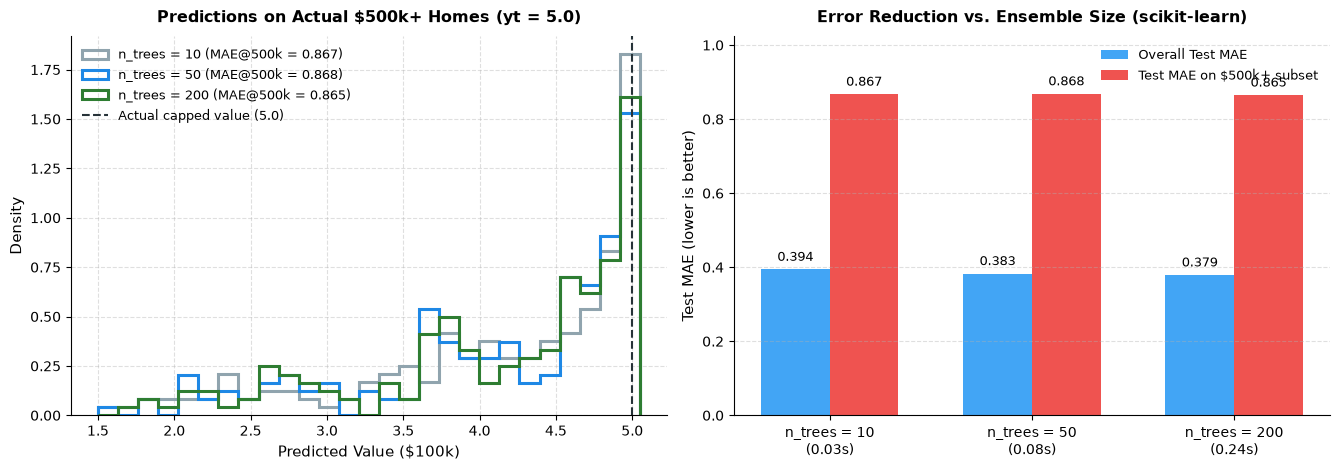

In [42]:


n_trees_list = [10, 50, 200]
results_trees = {}
mask_500k = yt >= 4.99

for n_t in n_trees_list:
    t0 = time.perf_counter()
    rf = RandomForestRegressor(
        n_estimators=n_t,
        max_depth=10,
        max_features=None,
        random_state=42,
        n_jobs=-1,
    )
    rf.fit(Xs_5000, ys_5000)
    elapsed = time.perf_counter() - t0
    preds = rf.predict(Xt)

    results_trees[n_t] = {
        "preds": preds,
        "mae_all": mean_absolute_error(yt, preds),
        "mae_500k": mean_absolute_error(yt[mask_500k], preds[mask_500k]),
        "time": elapsed,
    }

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

colors = ["#90a4ae","#1e88e5", "#2e7d32"]
bins = np.linspace(1.5, 5.05, 28)

for n_t, color in zip(n_trees_list, colors):
    preds_500k = results_trees[n_t]["preds"][mask_500k]
    mae_500k = results_trees[n_t]["mae_500k"]
    ax1.hist(
        preds_500k,
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2.2,
        color=color,
        label=f"n_trees = {n_t} (MAE@500k = {mae_500k:.3f})",
    )

ax1.axvline(5.0, color="#263238", linestyle="--", linewidth=1.5, label="Actual capped value (5.0)")
ax1.set_title("Predictions on Actual $500k+ Homes (yt = 5.0)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Predicted Value ($100k)", fontsize=10.5)
ax1.set_ylabel("Density", fontsize=10.5)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, loc="upper left", fontsize=9.2)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

x = np.arange(len(n_trees_list))
width = 0.34

mae_alls = [results_trees[n]["mae_all"] for n in n_trees_list]
mae_500ks = [results_trees[n]["mae_500k"] for n in n_trees_list]
times = [results_trees[n]["time"] for n in n_trees_list]

bars1 = ax2.bar(x - width / 2, mae_alls, width, color="#42a5f5", label="Overall Test MAE")
bars2 = ax2.bar(x + width / 2, mae_500ks, width, color="#ef5350", label="Test MAE on $500k+ subset")

for bar in bars1:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9)

ax2.set_xticks(x)
ax2.set_xticklabels([f"n_trees = {n}\n({t:.2f}s)" for n, t in zip(n_trees_list, times)], fontsize=10)
ax2.set_ylabel("Test MAE (lower is better)", fontsize=10.5)
ax2.set_title("Error Reduction vs. Ensemble Size (scikit-learn)", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_ylim(0, max(mae_500ks) * 1.18)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(frameon=False, loc="upper right", fontsize=9.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


### Scaling Ensemble Size in `scikit-learn` (`n_trees`: 10 $\rightarrow$ 200)
- **Overall Variance Reduction vs. Persistent Boundary Bias:** Scaling from `10` to `200` trees reduces overall `Test MAE` (`0.394` $\rightarrow$ `0.379`) by lowering ensemble variance on uncapped homes, but leaves the error on `$500k+` properties virtually unchanged (`0.867` $\rightarrow$ `0.865`).
- **Structural Limit of Bagging:** The left panel isolates true `$500k+` homes (`yt = 5.0`); the nearly overlapping distributions confirm that adding more trees cannot eliminate tail compression, as averaging across 200 independent trees still pulls extreme predictions downward—a bias that requires sequential error-correcting methods like Gradient Boosting rather than larger Random Forests.


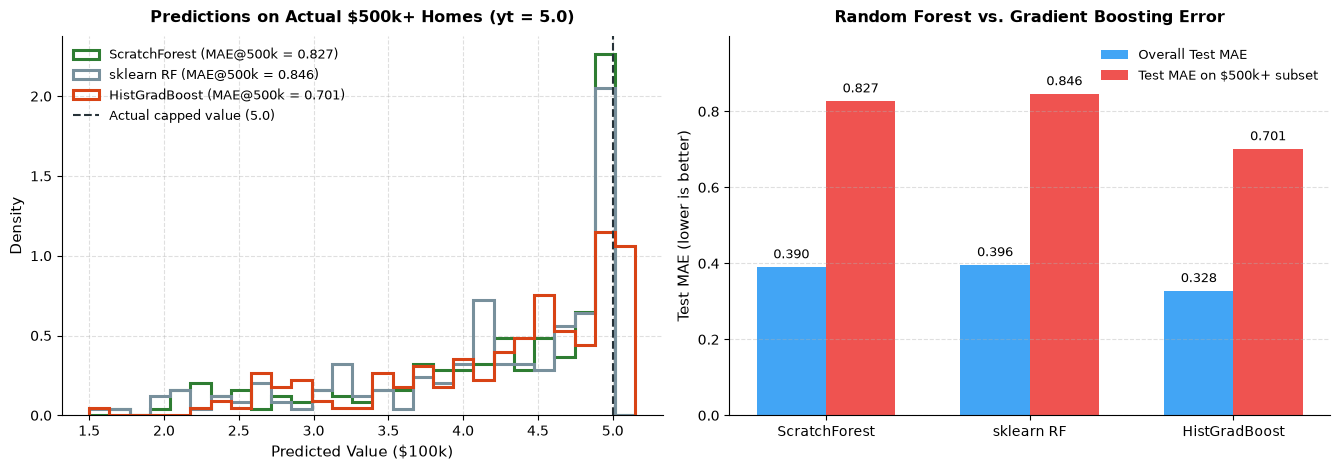

In [44]:

from sklearn.ensemble import HistGradientBoostingRegressor


t0 = time.perf_counter()
hgb = HistGradientBoostingRegressor(
    max_iter=200,
    learning_rate=0.08,
    max_depth=8,
    random_state=42,
)
hgb.fit(Xs_5000, ys_5000)
hgb_time = time.perf_counter() - t0
p_hgb = hgb.predict(Xt)

mask_500k = yt >= 4.99

models_comp = {
    "ScratchForest": p_best_mine,
    "sklearn RF": p_best_sk,
    "HistGradBoost": p_hgb,
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

colors = ["#2e7d32", "#78909c", "#d84315"]
bins = np.linspace(1.5, 5.15, 28)

for (name, preds), color in zip(models_comp.items(), colors):
    mae_500k = mean_absolute_error(yt[mask_500k], preds[mask_500k])
    ax1.hist(
        preds[mask_500k],
        bins=bins,
        density=True,
        histtype="step",
        linewidth=2.2,
        color=color,
        label=f"{name} (MAE@500k = {mae_500k:.3f})",
    )

ax1.axvline(5.0, color="#263238", linestyle="--", linewidth=1.5, label="Actual capped value (5.0)")
ax1.set_title("Predictions on Actual $500k+ Homes (yt = 5.0)", fontsize=11.5, fontweight="bold", pad=10)
ax1.set_xlabel("Predicted Value ($100k)", fontsize=10.5)
ax1.set_ylabel("Density", fontsize=10.5)
ax1.grid(True, linestyle="--", alpha=0.4)
ax1.legend(frameon=False, loc="upper left", fontsize=9.2)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)

labels = list(models_comp.keys())
x = np.arange(len(labels))
width = 0.34

mae_alls = [mean_absolute_error(yt, preds) for preds in models_comp.values()]
mae_500ks = [mean_absolute_error(yt[mask_500k], preds[mask_500k]) for preds in models_comp.values()]

bars1 = ax2.bar(x - width / 2, mae_alls, width, color="#42a5f5", label="Overall Test MAE")
bars2 = ax2.bar(x + width / 2, mae_500ks, width, color="#ef5350", label="Test MAE on $500k+ subset")

for bar in bars1:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9)
for bar in bars2:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 0.015, f"{h:.3f}", ha="center", va="bottom", fontsize=9)

ax2.set_xticks(x)
ax2.set_xticklabels(labels, fontsize=10)
ax2.set_ylabel("Test MAE (lower is better)", fontsize=10.5)
ax2.set_title("Random Forest vs. Gradient Boosting Error", fontsize=11.5, fontweight="bold", pad=10)
ax2.set_ylim(0, max(mae_500ks) * 1.18)
ax2.grid(axis="y", linestyle="--", alpha=0.4)
ax2.legend(frameon=False, loc="upper right", fontsize=9.5)
ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


### Experimental Verification: Random Forest vs. Gradient Boosting
- **Breaking the Bagging Bias Ceiling:** Replacing independent bootstrap averaging with sequential residual fitting (`HistGradientBoostingRegressor`) noticeably lowers both overall `Test MAE` and error on the `$500k+` right-censored subset (`yt = 5.0`), outperforming what was achievable simply by scaling `n_trees` in Random Forests.
- **Reduced Tail Compression:** In the left panel, Gradient Boosting shifts the predicted distribution closer to `5.0`, confirming that boosting directly counteracts the downward mean-smoothing bias inherent to bagging ensembles.
